# Лабораторна робота №7
## Глибоке навчання для оброблення складних даних

**Мета:** виконати побудову, навчання та оцінювання моделі глибокого навчання для оброблення складних даних; дослідити згорткову нейронну мережу CNN для класифікації зображень, вплив архітектури і параметрів навчання на якість моделі.

Тип даних - зображення, тому використано **CNN** (TensorFlow/Keras). Набір даних - **Fashion-MNIST**, той самий, що в ЛР6, щоб порівняти згорткову мережу з багатошаровим перцептроном.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import tensorflow as tf

## 1. Набір даних

In [2]:
from tensorflow.keras.datasets import fashion_mnist

(X_full, y_full), (X_test, y_test) = fashion_mnist.load_data()

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

print("Навчальна частина:", X_full.shape)
print("Тестова частина:", X_test.shape)

Навчальна частина: (60000, 28, 28)
Тестова частина: (10000, 28, 28)


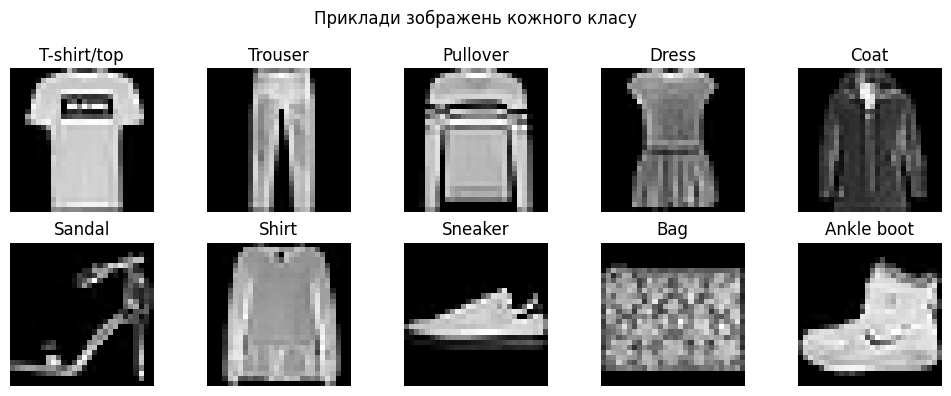

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for i, ax in enumerate(axes.ravel()):
    index = np.where(y_full == i)[0][0]
    ax.imshow(X_full[index], cmap="gray")
    ax.set_title(class_names[i])
    ax.axis("off")

plt.suptitle("Приклади зображень кожного класу")
plt.tight_layout()
plt.show()

## 2. Попередній аналіз набору даних

In [4]:
print("Розмір одного зображення:", X_full.shape[1:])
print("Тип даних:", X_full.dtype)
print("Діапазон пікселів:", X_full.min(), "-", X_full.max())
print("Пропусків:", np.isnan(X_full).sum() + np.isnan(X_test).sum())
print("Кількість класів:", len(np.unique(y_full)))

pd.DataFrame({
    "Клас": class_names,
    "Train": np.bincount(y_full),
    "Test": np.bincount(y_test)
})

Розмір одного зображення: (28, 28)
Тип даних: uint8
Діапазон пікселів: 0 - 255
Пропусків: 0
Кількість класів: 10


,Клас,Train,Test
0,T-shirt/top,6000,1000
1,Trouser,6000,1000
2,Pullover,6000,1000
3,Dress,6000,1000
4,Coat,6000,1000
5,Sandal,6000,1000
6,Shirt,6000,1000
7,Sneaker,6000,1000
8,Bag,6000,1000
9,Ankle boot,6000,1000


**Структура вхідних даних:** кожен об'єкт - чорно-біле зображення 28×28 пікселів (один канал яскравості), тип `uint8`, значення від 0 до 255. На відміну від ЛР6, тут зображення не розгортається у вектор: CNN працює з ним як з двовимірною картинкою і враховує, які пікселі є сусідами.

**Вихідні дані:** номер класу від 0 до 9, тобто задача багатокласової класифікації на 10 класів. Пропусків немає, класи повністю збалансовані: по 6000 зображень у навчальній частині і по 1000 у тестовій.

## 3. Підготовка даних

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_full, y_full, test_size=0.2, random_state=42, stratify=y_full
)

X_train = X_train.astype("float32")[..., None] / 255
X_val = X_val.astype("float32")[..., None] / 255
X_test = X_test.astype("float32")[..., None] / 255

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)
print("Діапазон після нормалізації:", X_train.min(), "-", X_train.max())

Train: (48000, 28, 28, 1) (48000,)
Validation: (12000, 28, 28, 1) (12000,)
Test: (10000, 28, 28, 1) (10000,)
Діапазон після нормалізації: 0.0 - 1.0


- **Поділ:** готова тестова вибірка (10 000) відкладена до кінця, навчальна частина поділена 80/20 зі `stratify` на train (48 000) і validation (12 000), як у ЛР6.
- **Нормалізація:** значення пікселів поділено на 255, тепер вони від 0 до 1. Число 255 фіксоване, тому витоку даних немає.
- **Канал:** `[..., None]` додає вісь каналу, і форма стає (28, 28, 1), бо шар `Conv2D` очікує зображення з каналами (1 для чорно-білих, 3 для кольорових).
- **Зміна розміру не потрібна:** усі зображення вже 28×28.
- **Аугментація не виконувалась.** У завданні вона потрібна «за необхідності», а зображення Fashion-MNIST уже центровані, однакового розміру й орієнтації. Повороти чи віддзеркалення можуть зробити приклади нетиповими для набору або навіть змінити зміст (черевик, повернутий догори, вже не схожий на черевик), а навчання помітно подовжиться. Від перенавчання тут захищає Dropout.
- Токенізація і часові вікна стосуються текстів і послідовностей, тому для зображень не потрібні.

## 4. Побудова базової CNN

In [6]:
tf.keras.utils.set_random_seed(42)

base_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(32, 3, activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D(2),
    tf.keras.layers.Conv2D(64, 3, activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D(2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(10, activation="softmax")
])

base_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

## 5. Параметри архітектури

- **Згортковий блок 1:** `Conv2D(32, 3)` - 32 фільтри розміром 3×3, кожен «ковзає» по зображенню і створює свою карту ознак. `padding="same"` доповнює межі нулями, щоб розмір не зменшувався (28×28), активація ReLU. Далі `MaxPooling2D(2)` бере максимум у кожному квадраті 2×2 і зменшує карти до 14×14. Параметрів (3·3·1 + 1)·32 = 320.
- **Згортковий блок 2:** `Conv2D(64, 3)` - 64 фільтри, які комбінують 32 карти попереднього шару (параметрів (3·3·32 + 1)·64 = 18 496), потім MaxPooling до 7×7.
- **Flatten:** 7·7·64 = 3136 значень у вектор.
- **Повнозв'язна частина:** `Dense(128, relu)` (401 536 параметрів - найбільша частина моделі), `Dropout(0.3)` вимикає 30% нейронів під час навчання, і вихідний шар `Dense(10, softmax)` дає ймовірності 10 класів.

Разом **421 642** параметри. Перший згортковий шар шукає прості ознаки (краї, лінії), другий - їх комбінації (частини предметів).

## 6. Налаштування процесу навчання

In [7]:
LEARNING_RATE = 0.001
BATCH_SIZE = 128
EPOCHS = 15

base_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Learning rate:", LEARNING_RATE)
print("Batch size:", BATCH_SIZE)
print("Кількість епох:", EPOCHS)

Learning rate: 0.001
Batch size: 128
Кількість епох: 15


Функція втрат `sparse_categorical_crossentropy` - Cross-Entropy для 10 класів з мітками-числами. Оптимізатор Adam з learning rate 0.001, batch size 128 (375 оновлень ваг за епоху), 15 епох. Епох менше, ніж у ЛР6 (20), бо одна епоха CNN триває близько 10 с замість 1.5 с, а CNN навчається швидше.

## 7. Навчання базової моделі

In [8]:
start = time.time()
base_history = base_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=2
)
base_time = time.time() - start

print("Час навчання, с:", round(base_time, 1))

Epoch 1/15


375/375 - 9s - 25ms/step - accuracy: 0.7972 - loss: 0.5664 - val_accuracy: 0.8645 - val_loss: 0.3618


Epoch 2/15


375/375 - 11s - 28ms/step - accuracy: 0.8730 - loss: 0.3527 - val_accuracy: 0.8978 - val_loss: 0.2880


Epoch 3/15


375/375 - 11s - 30ms/step - accuracy: 0.8916 - loss: 0.3014 - val_accuracy: 0.9059 - val_loss: 0.2601


... (21 outputs left out)

375/375 - 10s - 27ms/step - accuracy: 0.9523 - loss: 0.1266 - val_accuracy: 0.9265 - val_loss: 0.2313


Epoch 15/15


375/375 - 10s - 27ms/step - accuracy: 0.9547 - loss: 0.1188 - val_accuracy: 0.9244 - val_loss: 0.2319


Час навчання, с: 152.2


In [9]:
history_table = pd.DataFrame(base_history.history)
history_table.index = history_table.index + 1
history_table.index.name = "Епоха"
history_table.round(4)

,accuracy,loss,val_accuracy,val_loss
Епоха,,,,
1,0.7972,0.5664,0.8645,0.3618
2,0.8730,0.3527,0.8978,0.2880
3,0.8916,0.3014,0.9059,0.2601
4,0.8999,0.2753,0.9121,0.2478
5,0.9070,0.2491,0.9152,0.2388
6,0.9152,0.2299,0.9178,0.2343
7,0.9210,0.2125,0.9237,0.2268
8,0.9266,0.1988,0.9235,0.2194
9,0.9323,0.1823,0.9241,0.2211


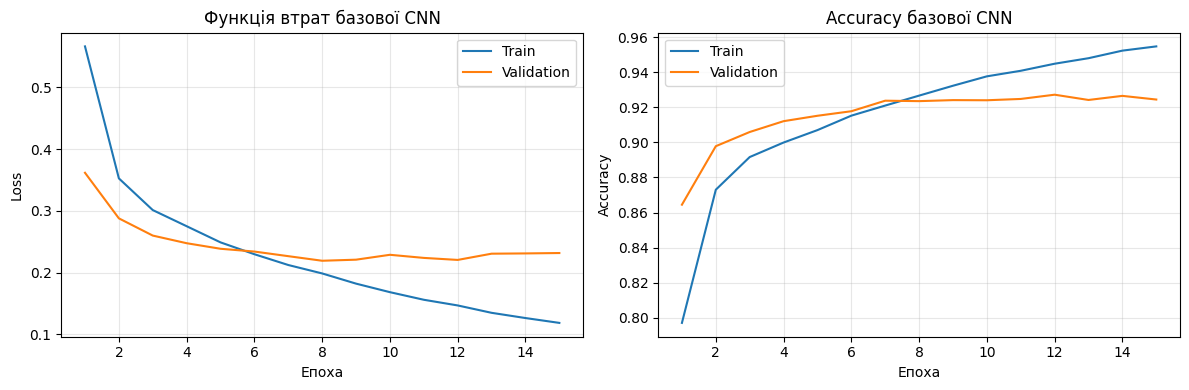

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_table.index, history_table["loss"], label="Train")
axes[0].plot(history_table.index, history_table["val_loss"], label="Validation")
axes[0].set_title("Функція втрат базової CNN")
axes[0].set_xlabel("Епоха")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history_table.index, history_table["accuracy"], label="Train")
axes[1].plot(history_table.index, history_table["val_accuracy"], label="Validation")
axes[1].set_title("Accuracy базової CNN")
axes[1].set_xlabel("Епоха")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [11]:
best_epoch = int(history_table["val_loss"].idxmin())

print("Епоха з найменшим val loss:", best_epoch)
print("Найменший val loss:", round(history_table["val_loss"].min(), 4))
print("Найкраща val accuracy:", round(history_table["val_accuracy"].max(), 4))
print("Train accuracy на останній епосі:", round(history_table["accuracy"].iloc[-1], 4))
print("Val accuracy на останній епосі:", round(history_table["val_accuracy"].iloc[-1], 4))

Епоха з найменшим val loss: 8
Найменший val loss: 0.2194
Найкраща val accuracy: 0.9272
Train accuracy на останній епосі: 0.9547
Val accuracy на останній епосі: 0.9244


Базова CNN навчалась 152 с (близько 10 с на епоху). Уже після першої епохи val accuracy становить 0.865, а після третьої 0.906, тобто більше, ніж MLP з ЛР6 досягав за 20 епох (близько 0.89).

Найменший val loss **0.2194** досягнуто на **8-й епосі**, найкраща val accuracy **0.9272** на 12-й. Після 8-ї епохи train loss продовжує падати (до 0.119), а val loss повільно росте до 0.232. Train accuracy доходить до 0.955, а val accuracy тримається близько 0.924-0.927. Тобто з'являються **ознаки перенавчання** (розрив train - val 3%), але слабші, ніж у MLP: val loss росте повільно, бо Dropout 0.3 і сама структура згорток стримують перенавчання. Недонавчання немає.

## 8. Додаткові експерименти

In [12]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []
histories = {"Базова (32, 64, Dropout 0.3)": base_history.history}
trained_models = {"Базова (32, 64, Dropout 0.3)": base_model}

val_pred = base_model.predict(X_val, verbose=0).argmax(axis=1)
results.append({
    "Модель": "Базова (32, 64, Dropout 0.3)",
    "Параметри": base_model.count_params(),
    "Train accuracy": base_history.history["accuracy"][-1],
    "Val accuracy": accuracy_score(y_val, val_pred),
    "Найкращий val loss": min(base_history.history["val_loss"]),
    "Precision": precision_score(y_val, val_pred, average="macro"),
    "Recall": recall_score(y_val, val_pred, average="macro"),
    "F1-score": f1_score(y_val, val_pred, average="macro"),
    "Час, с": base_time
})

experiments = {
    "Dropout 0.5 (32, 64)": ([32, 64], 0.5),
    "Більше фільтрів (64, 128)": ([64, 128], 0.3)
}

for name, (filters, dropout) in experiments.items():
    tf.keras.utils.set_random_seed(42)

    model = tf.keras.Sequential()
    model.add(tf.keras.layers.Input(shape=(28, 28, 1)))
    for f in filters:
        model.add(tf.keras.layers.Conv2D(f, 3, activation="relu", padding="same"))
        model.add(tf.keras.layers.MaxPooling2D(2))
    model.add(tf.keras.layers.Flatten())
    model.add(tf.keras.layers.Dense(128, activation="relu"))
    model.add(tf.keras.layers.Dropout(dropout))
    model.add(tf.keras.layers.Dense(10, activation="softmax"))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    start = time.time()
    history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                        epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0)
    elapsed = time.time() - start

    val_pred = model.predict(X_val, verbose=0).argmax(axis=1)
    results.append({
        "Модель": name,
        "Параметри": model.count_params(),
        "Train accuracy": history.history["accuracy"][-1],
        "Val accuracy": accuracy_score(y_val, val_pred),
        "Найкращий val loss": min(history.history["val_loss"]),
        "Precision": precision_score(y_val, val_pred, average="macro"),
        "Recall": recall_score(y_val, val_pred, average="macro"),
        "F1-score": f1_score(y_val, val_pred, average="macro"),
        "Час, с": elapsed
    })
    histories[name] = history.history
    trained_models[name] = model
    print(name, "- навчено за", round(elapsed, 1), "с")

Dropout 0.5 (32, 64) - навчено за 151.4 с


Більше фільтрів (64, 128) - навчено за 431.3 с


## 9. Порівняння базової та модифікованих моделей

In [13]:
results_table = pd.DataFrame(results)
results_table["Train - Val"] = results_table["Train accuracy"] - results_table["Val accuracy"]
results_table.round(4)

,Модель,Параметри,Train accuracy,Val accuracy,Найкращий val loss,Precision,Recall,F1-score,"Час, с",Train - Val
0,"Базова (32, 64, Dropout 0.3)",421642,0.9547,0.9244,0.2194,0.9275,0.9244,0.9252,152.1828,0.0303
1,"Dropout 0.5 (32, 64)",421642,0.9410,0.9277,0.2148,0.9282,0.9277,0.9277,151.3871,0.0134
2,"Більше фільтрів (64, 128)",878730,0.9684,0.9246,0.2193,0.9274,0.9246,0.9252,431.2648,0.0438


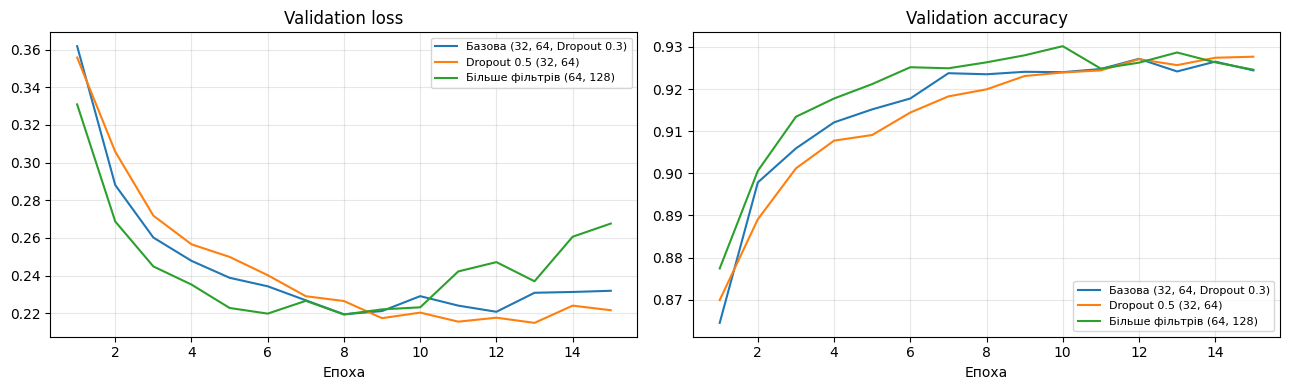

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for name, history in histories.items():
    axes[0].plot(range(1, EPOCHS + 1), history["val_loss"], label=name)
    axes[1].plot(range(1, EPOCHS + 1), history["val_accuracy"], label=name)

axes[0].set_title("Validation loss")
axes[1].set_title("Validation accuracy")
for ax in axes:
    ax.set_xlabel("Епоха")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

| Модель | Параметри | Val accuracy | F1 (val) | Найкращий val loss | Train - Val | Час |
|---|---|---|---|---|---|---|
| Базова (32, 64, Dropout 0.3) | 421 642 | 0.9244 | 0.9252 | 0.2194 | 0.030 | 152 с |
| **Dropout 0.5** | 421 642 | **0.9277** | **0.9277** | **0.2148** | **0.013** | 151 с |
| Більше фільтрів (64, 128) | 878 730 | 0.9246 | 0.9252 | 0.2193 | 0.044 | 431 с |

- **Dropout 0.5** дав найкращий результат за всіма показниками: val accuracy 0.9277, найменший val loss 0.2148 і найменший розрив train - val (0.013). На графіку його val loss майже не росте до кінця навчання. Сильніший Dropout трохи сповільнив навчання на перших епохах (крива accuracy спочатку нижча), але зате прибрав перенавчання. Час навчання не змінився.
- **Більше фільтрів (64, 128)** удвічі збільшило кількість параметрів і майже втричі час навчання (431 с). Ця модель найшвидше вчиться (на 10-й епосі val accuracy 0.930), але потім найсильніше перенавчається: val loss росте з 0.22 до 0.27, а розрив train - val 0.044. На 15-й епосі її якість така сама, як у базової.

Висновок: для цієї задачі важливіше контролювати перенавчання, ніж збільшувати модель.

## 10. Оцінювання найкращої моделі на тестовій вибірці

In [15]:
from sklearn.metrics import classification_report, confusion_matrix

best_name = results_table.loc[results_table["F1-score"].idxmax(), "Модель"]
best_model = trained_models[best_name]

test_pred = best_model.predict(X_test, verbose=0).argmax(axis=1)

print("Найкраща модель:", best_name)
print("Accuracy:", round(accuracy_score(y_test, test_pred), 4))
print("Precision (macro):", round(precision_score(y_test, test_pred, average="macro"), 4))
print("Recall (macro):", round(recall_score(y_test, test_pred, average="macro"), 4))
print("F1-score (macro):", round(f1_score(y_test, test_pred, average="macro"), 4))
print()
print(classification_report(y_test, test_pred, target_names=class_names, digits=3))

Найкраща модель: Dropout 0.5 (32, 64)
Accuracy: 0.9198
Precision (macro): 0.9203
Recall (macro): 0.9198
F1-score (macro): 0.9197

              precision    recall  f1-score   support

 T-shirt/top      0.855     0.868     0.862      1000
     Trouser      0.990     0.988     0.989      1000
    Pullover      0.900     0.850     0.874      1000
       Dress      0.932     0.913     0.922      1000
        Coat      0.839     0.931     0.882      1000
      Sandal      0.993     0.984     0.988      1000
       Shirt      0.766     0.738     0.752      1000
     Sneaker      0.962     0.976     0.969      1000
         Bag      0.992     0.976     0.984      1000
  Ankle boot      0.975     0.974     0.974      1000

    accuracy                          0.920     10000
   macro avg      0.920     0.920     0.920     10000
weighted avg      0.920     0.920     0.920     10000



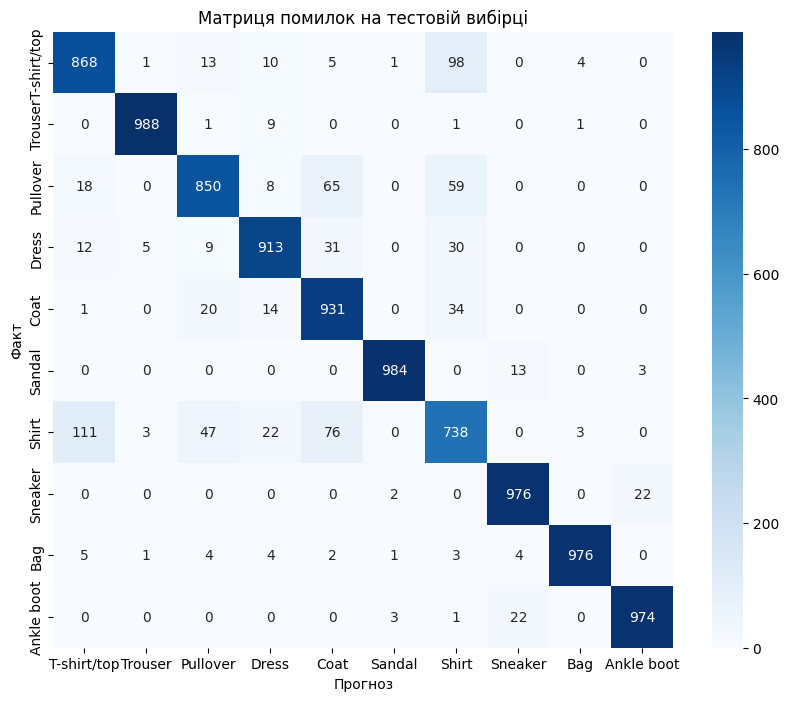

In [16]:
plt.figure(figsize=(10, 8))
sns.heatmap(confusion_matrix(y_test, test_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.title("Матриця помилок на тестовій вибірці")
plt.xlabel("Прогноз")
plt.ylabel("Факт")
plt.show()

Найкраща за F1 на валідації модель - **CNN з Dropout 0.5**. На тестовій вибірці: **Accuracy 0.9198, Precision 0.9203, Recall 0.9198, F1-score 0.9197** (macro). Це лише на 0.8% нижче, ніж на валідації, тобто модель добре узагальнює на нових даних.

**Метрики по класах:**
- найкраще розпізнаються Trouser (F1 0.989), Sandal (0.988), Bag (0.984), Ankle boot (0.974), Sneaker (0.969);
- найгірше Shirt (0.752), далі T-shirt/top (0.862), Pullover (0.874) і Coat (0.882).

**Матриця помилок** показує ті самі пари, що й у ЛР6, але помилок менше: сорочки плутаються з футболками (111), пальтами (76) і пуловерами (47), футболки з сорочками (98), пуловери з пальтами (65) і сорочками (59). Взуття майже не плутається з одягом, лише кросівки з черевиками (по 22).

**Порівняння з MLP з ЛР6:** MLP мав на тесті accuracy 0.883 і F1 0.883, CNN - 0.920 і 0.920, тобто **на 3.7% краще**. Найбільше покращення для складних класів: Shirt з 0.702 до 0.752, Pullover з 0.775 до 0.874, Coat з 0.800 до 0.882.

## 11. Візуалізація результатів

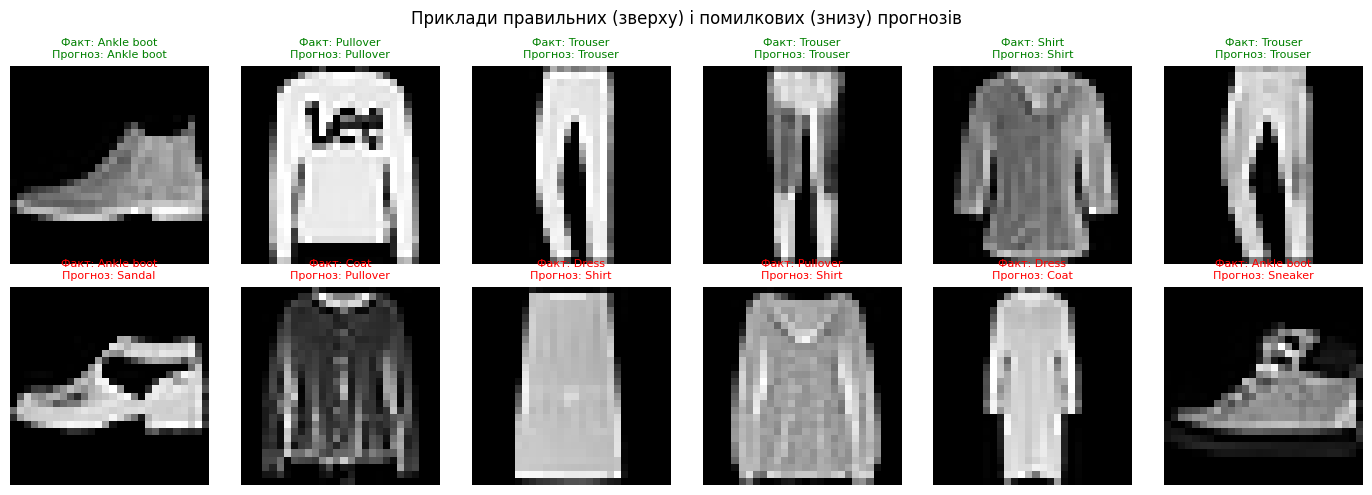

In [17]:
correct = np.where(test_pred == y_test)[0][:6]
wrong = np.where(test_pred != y_test)[0][:6]

fig, axes = plt.subplots(2, 6, figsize=(14, 5))

for ax, index in zip(axes[0], correct):
    ax.imshow(X_test[index, :, :, 0], cmap="gray")
    ax.set_title("Факт: " + class_names[y_test[index]] + "\nПрогноз: " + class_names[test_pred[index]], fontsize=8, color="green")
    ax.axis("off")

for ax, index in zip(axes[1], wrong):
    ax.imshow(X_test[index, :, :, 0], cmap="gray")
    ax.set_title("Факт: " + class_names[y_test[index]] + "\nПрогноз: " + class_names[test_pred[index]], fontsize=8, color="red")
    ax.axis("off")

plt.suptitle("Приклади правильних (зверху) і помилкових (знизу) прогнозів")
plt.tight_layout()
plt.show()

Розмір карт ознак першого шару: (1, 28, 28, 32)


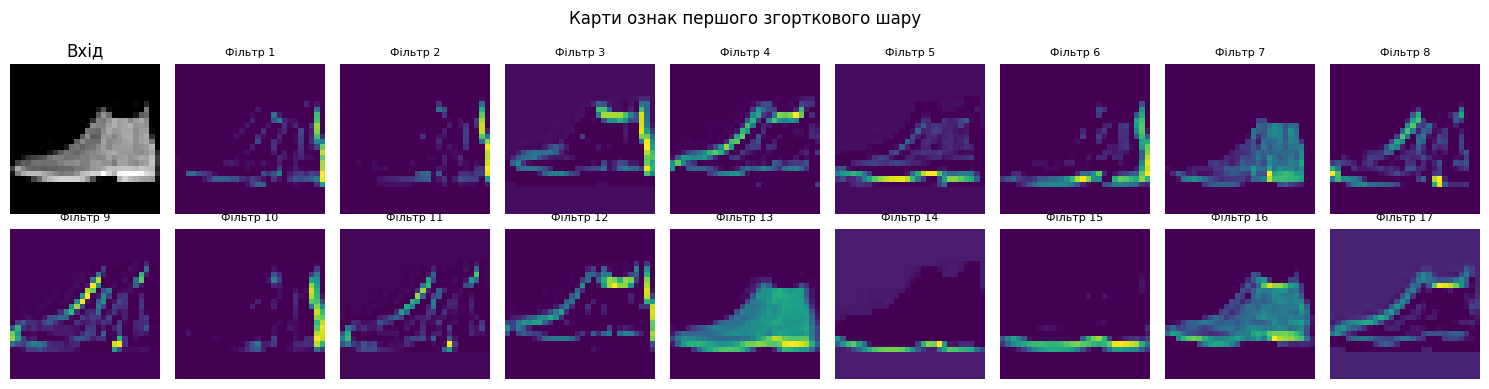

In [18]:
first_conv = tf.keras.Model(inputs=best_model.inputs, outputs=best_model.layers[0].output)
feature_maps = first_conv.predict(X_test[:1], verbose=0)

print("Розмір карт ознак першого шару:", feature_maps.shape)

fig, axes = plt.subplots(2, 9, figsize=(15, 4))
axes[0, 0].imshow(X_test[0, :, :, 0], cmap="gray")
axes[0, 0].set_title("Вхід")

for i, ax in enumerate(axes.ravel()[1:]):
    ax.imshow(feature_maps[0, :, :, i], cmap="viridis")
    ax.set_title("Фільтр " + str(i + 1), fontsize=8)

for ax in axes.ravel():
    ax.axis("off")

plt.suptitle("Карти ознак першого згорткового шару")
plt.tight_layout()
plt.show()

**Приклади прогнозів.** У верхньому рядку правильні прогнози (зелені підписи): черевик, пуловер, штани, сорочка. У нижньому помилкові (червоні): пальто, яке мережа назвала пуловером, сукня як сорочка, пуловер як сорочка, сукня як пальто, черевик як сандаль і кросівок. Майже всі помилки зрозумілі навіть людині: на картинці 28×28 пальто і пуловер, сукня і сорочка справді схожі за формою, а черевик з вирізами схожий на сандаль.

**Карти ознак першого шару.** Для першого тестового зображення (черевик) показано 17 з 32 карт ознак. Кожен фільтр реагує на свою ознаку: одні виділяють вертикальні краї (фільтри 1, 2, 10 - права межа черевика), інші горизонтальні (фільтри 14, 15 - підошва), похилі лінії (фільтри 8, 9, 11 - верх черевика) або заповнену область предмета (фільтри 7, 13, 16). Саме це і означає, що початкові шари CNN виділяють прості ознаки - краї і контури, а наступні шари комбінують їх у складніші.

## 12. Висновки

- **Ефективність CNN.** Згорткова мережа добре підходить для зображень: вона враховує просторову структуру (сусідні пікселі), а фільтри самі навчаються виділяти краї, контури і частини предметів. Найкраща модель має на тестовій вибірці accuracy **0.920** і F1 **0.920**, тоді як MLP з ЛР6 на тих самих даних мав 0.883, тобто CNN на 3.7% точніша. При цьому CNN уже після 3 епох перевершила результат MLP за 20 епох.
- **Вплив параметрів.** Збільшення Dropout з 0.3 до 0.5 покращило val accuracy (0.9244 -> 0.9277) і зменшило розрив train - val з 3.0% до 1.3%, не змінивши ні кількість параметрів, ні час. Подвоєння кількості фільтрів (64, 128) удвічі збільшило модель і майже втричі час навчання, але після 10-ї епохи вона сильніше перенавчалась, і в підсумку якість не покращилась. Отже, для цієї задачі регуляризація важливіша за розмір мережі.
- **Узагальнення.** Різниця між валідацією і тестом лише 0.8% (0.9277 і 0.9198), тому модель добре працює на раніше невідомих даних. Залишкові помилки стосуються схожих предметів верхнього одягу (сорочка, футболка, пуловер, пальто), які на зображенні 28×28 важко відрізнити навіть людині: найгірший клас Shirt (F1 0.752).
- **Найкраща модель:** CNN з двома згортковими блоками (32 і 64 фільтри), Dense(128) і Dropout 0.5, 421 642 параметри.